# The Attribution Gap: Perceived vs. Actual Economic Change

Links CES 2024 respondents to the county economic record from notebooks 04–05 and asks three questions:

1. **Does local economic reality move perception at all?** Regress each respondent's retrospective evaluation of the economy on the measured 2020→2024 change in their county.
2. **What explains the gap?** The residual from (1) is the *attribution gap* — how much better or worse a respondent says things went than their county's record would predict. Describe it by partisanship, media diet, education, and county type.
3. **Does the gap predict vote switching?** Among 2024 respondents who recall voting for Biden in 2020, does a more negative gap predict voting for Trump in 2024?

This notebook is descriptive and single-level. The multilevel model (respondents nested in counties, cross-level media interactions) is notebook 07.

**Inputs:** `data/raw/ces/ces_2024.csv`, `data/raw/ces/ces_2016_2024_core.csv`, `data/processed/county_covariates.csv`

**Coding references** (all verified against `data/raw/ces/CES_2024_GUIDE_vv.pdf`):
- `econ_retro` (CC24_301): 1 much better … 5 much worse, 6 not sure
- `pid7`: 1 strong Dem … 4 independent … 7 strong Rep, 8 not sure
- `q300_1..5` (past 24 hrs, 1 = yes): social media, TV news, newspaper, radio, none
- `q300a` (TV type): 1 local, 2 national, 3 both
- `q300b_1..8` (networks, 1 = yes): ABC, CBS, NBC, CNN, Fox, MSNBC, PBS, other
- `educ`: 1 no HS, 2 HS, 3 some college, 4 two-year, 5 four-year, 6 post-grad
- Weights: `weight` for pre-election items (all 60,000), `weight_post` for post-election items (49,432)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

RAW_DIR     = Path('../data/raw')
PROC_DIR    = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures')
TABLES_DIR  = Path('../outputs/tables')
for d in [PROC_DIR, FIGURES_DIR, TABLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def wmean(x, w):
    m = x.notna() & w.notna()
    return np.average(x[m], weights=w[m]) if m.any() else np.nan

## 1. Load and recode CES 2024

In [2]:
ces = pd.read_csv(RAW_DIR / 'ces' / 'ces_2024.csv', low_memory=False)
print(f'CES 2024: {len(ces):,} respondents')

# Perceived change, signed: +2 much better ... -2 much worse; 'not sure' -> NaN
def signed(col):
    s = ces[col].where(ces[col].between(1, 5))
    return 3 - s
ces['perceived_econ']   = signed('econ_retro')
ces['perceived_income'] = signed('hh_income_retro')
ces['perceived_prices'] = signed('prices_retro')   # +2 = prices decreased a lot, -2 = increased a lot

# Partisanship
ces['pid7c'] = ces['pid7'].where(ces['pid7'].between(1, 7))
ces['pid3c'] = pd.cut(ces['pid7c'], [0, 3, 4, 7], labels=['Dem', 'Ind', 'Rep'])

# Media diet (past 24 hours)
ces['social']    = (ces['q300_1'] == 1).astype(int)
ces['tv_news']   = (ces['q300_2'] == 1).astype(int)
ces['newspaper'] = (ces['q300_3'] == 1).astype(int)
ces['radio']     = (ces['q300_4'] == 1).astype(int)
ces['no_news']   = (ces['q300_5'] == 1).astype(int)
ces['local_tv']  = ces['q300a'].isin([1, 3]).astype(int)
for name, col in [('cnn', 'q300b_4'), ('fox', 'q300b_5'), ('msnbc', 'q300b_6')]:
    ces[name] = (ces[col] == 1).astype(int)   # 0 for non-TV-watchers

# Demographics
ces['college'] = (ces['educ'] >= 5).astype(int)
ces['age']     = 2024 - ces['birthyr']
ces['white']   = ((ces['race'] == 1) & (ces['hispanic'] != 1)).astype(int)

# Vote
ces['voted_2024'] = ces['presvote_post_party'].isin(['D', 'R'])
ces['vote_R_2024'] = np.where(ces['voted_2024'], (ces['presvote_post_party'] == 'R').astype(float), np.nan)
ces['prior_D'] = ces['presvote_prior_party'] == 'D'
ces['prior_R'] = ces['presvote_prior_party'] == 'R'

print('perceived_econ (weighted):', {k: round(v, 3) for k, v in
      ces.groupby('perceived_econ').apply(lambda g: g['weight'].sum() / ces['weight'].sum()).items()})
print('pid3c (weighted):        ', {k: round(v, 3) for k, v in
      ces.groupby('pid3c').apply(lambda g: g['weight'].sum() / ces['weight'].sum()).items()})
print('watched Fox / MSNBC / CNN (weighted):',
      [round(wmean(ces[c], ces['weight']), 3) for c in ['fox', 'msnbc', 'cnn']])

CES 2024: 60,000 respondents
perceived_econ (weighted): {-2.0: 0.337, -1.0: 0.228, 0.0: 0.152, 1.0: 0.175, 2.0: 0.074}
pid3c (weighted):         {'Dem': 0.415, 'Ind': 0.153, 'Rep': 0.397}
watched Fox / MSNBC / CNN (weighted): [0.179, 0.099, 0.134]


## 2. Merge the county economic record

In [3]:
cov = pd.read_csv(PROC_DIR / 'county_covariates.csv')
county_cols = ['county_fips', 'state', 'log_income', 'college_share', 'white_nocollege', 'unemp_rate',
               'dem_share_2020', 'swing_2024', 'real_pay_pct_chg_2020_2024',
               'private_emp_pct_chg_2020_2024', 'mfg_share_2016', 'mfg_suppressed', 'population']
df = ces.merge(cov[county_cols], on='county_fips', how='left')

matched = df['real_pay_pct_chg_2020_2024'].notna()
print(f'Respondents matched to a county with QCEW data: {matched.sum():,} / {len(df):,} ({matched.mean():.1%})')
print(f'Counties represented: {df.loc[matched, "county_fips"].nunique():,}')
per = df[matched].groupby('county_fips').size()
print(f'Respondents per county: median {per.median():.0f}, >=20 in {(per >= 20).sum():,} counties, '
      f'>=50 in {(per >= 50).sum():,}')

# Standardize county 'actual' measures (population-weighted so a 1-SD move is a typical resident's experience)
for v in ['real_pay_pct_chg_2020_2024', 'private_emp_pct_chg_2020_2024', 'unemp_rate']:
    mu = wmean(cov[v], cov['population']); sd = np.sqrt(wmean((cov[v] - mu) ** 2, cov['population']))
    df[v + '_z'] = (df[v] - mu) / sd
df = df[matched].copy()

Respondents matched to a county with QCEW data: 59,219 / 60,000 (98.7%)
Counties represented: 2,671
Respondents per county: median 6, >=20 in 602 counties, >=50 in 272


## 3. The partisan flip, 2020 vs. 2024

Before asking whether local conditions matter, the baseline: retrospective evaluations track which party holds the White House. The same question was asked in 2020 (Trump incumbent) and 2024 (Biden incumbent).

Weighted mean perceived economic change (+2 much better ... -2 much worse):
pid3c   Dem   Ind   Rep   All
year                         
2016   0.43 -0.44 -0.65 -0.13
2020  -1.41 -0.83  0.11 -0.71
2024   0.32 -0.98 -1.37 -0.60


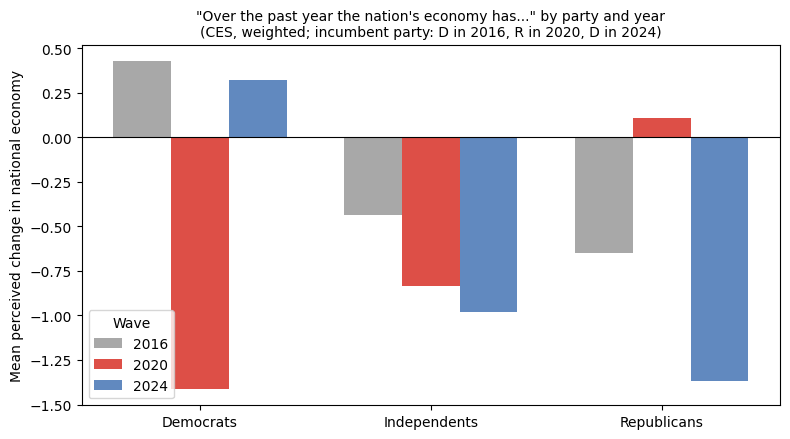

In [4]:
core = pd.read_csv(RAW_DIR / 'ces' / 'ces_2016_2024_core.csv', low_memory=False)
core['perceived_econ'] = 3 - core['econ_retro'].where(core['econ_retro'].between(1, 5))
core['pid3c'] = pd.cut(core['pid7'].where(core['pid7'].between(1, 7)), [0, 3, 4, 7], labels=['Dem', 'Ind', 'Rep'])

flip = core.groupby(['year', 'pid3c']).apply(lambda g: wmean(g['perceived_econ'], g['weight'])).unstack()
flip['All'] = core.groupby('year').apply(lambda g: wmean(g['perceived_econ'], g['weight']))
print('Weighted mean perceived economic change (+2 much better ... -2 much worse):')
print(flip.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(3); w = 0.25
for i, (yr, color) in enumerate([(2016, '#999999'), (2020, '#d73027'), (2024, '#4575b4')]):
    ax.bar(x + (i - 1) * w, flip.loc[yr, ['Dem', 'Ind', 'Rep']], w, label=f'{yr}', color=color, alpha=0.85)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(['Democrats', 'Independents', 'Republicans'])
ax.set_ylabel('Mean perceived change in national economy')
ax.set_title('"Over the past year the nation\'s economy has..." by party and year\n(CES, weighted; incumbent party: D in 2016, R in 2020, D in 2024)', fontsize=10)
ax.legend(title='Wave')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'attribution_partisan_flip.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Does local reality move perception?

Stage 1 regresses perceived change on the county's measured change, with survey weights and standard errors clustered by county. The R² is the share of perception explained by local economic reality. Adding party ID shows what perception actually tracks.

In [5]:
actual_rhs = 'real_pay_pct_chg_2020_2024_z + private_emp_pct_chg_2020_2024_z + unemp_rate_z'
d1 = df.dropna(subset=['perceived_econ', 'pid7c']).copy()
clus = {'groups': d1['county_fips']}

m_actual = smf.wls(f'perceived_econ ~ {actual_rhs}', data=d1, weights=d1['weight']).fit(cov_type='cluster', cov_kwds=clus)
m_party  = smf.wls('perceived_econ ~ pid7c', data=d1, weights=d1['weight']).fit(cov_type='cluster', cov_kwds=clus)
m_both   = smf.wls(f'perceived_econ ~ {actual_rhs} + pid7c', data=d1, weights=d1['weight']).fit(cov_type='cluster', cov_kwds=clus)

def tidy(m, name):
    return pd.DataFrame({f'{name}_coef': m.params, f'{name}_se': m.bse, f'{name}_p': m.pvalues})
stage1 = pd.concat([tidy(m_actual, 'actual'), tidy(m_party, 'party'), tidy(m_both, 'both')], axis=1).round(3)
print(f'N = {len(d1):,}')
print(f'R2  county actual only: {m_actual.rsquared:.4f}   party ID only: {m_party.rsquared:.3f}   both: {m_both.rsquared:.3f}\n')
stage1

N = 56,635
R2  county actual only: 0.0060   party ID only: 0.338   both: 0.341



,actual_coef,actual_se,actual_p,party_coef,party_se,party_p,both_coef,both_se,both_p
Intercept,-0.582,0.016,0.000,0.788,0.021,0.0,0.792,0.019,0.000
real_pay_pct_chg_2020_2024_z,-0.104,0.017,0.000,NaN,NaN,NaN,-0.027,0.009,0.002
private_emp_pct_chg_2020_2024_z,0.016,0.011,0.151,NaN,NaN,NaN,0.007,0.008,0.393
unemp_rate_z,-0.031,0.014,0.030,NaN,NaN,NaN,-0.067,0.009,0.000
pid7c,NaN,NaN,NaN,-0.348,0.004,0.0,-0.348,0.004,0.000


In [6]:
# Same test within party: does a 1-SD better county record move perception among Democrats? Republicans?
print('Effect of +1 SD county real pay growth on perceived economy, by party (cluster SEs):')
for p in ['Dem', 'Ind', 'Rep']:
    sub = d1[d1['pid3c'] == p]
    m = smf.wls(f'perceived_econ ~ {actual_rhs}', data=sub, weights=sub['weight']).fit(
        cov_type='cluster', cov_kwds={'groups': sub['county_fips']})
    b, se = m.params['real_pay_pct_chg_2020_2024_z'], m.bse['real_pay_pct_chg_2020_2024_z']
    print(f'  {p:4s}  N={len(sub):>6,}  mean perceived {wmean(sub["perceived_econ"], sub["weight"]):+.2f}   '
          f'real pay coef {b:+.3f} (se {se:.3f})   R2 {m.rsquared:.4f}')

Effect of +1 SD county real pay growth on perceived economy, by party (cluster SEs):
  Dem   N=28,302  mean perceived +0.32   real pay coef -0.021 (se 0.016)   R2 0.0069
  Ind   N= 7,368  mean perceived -0.98   real pay coef -0.036 (se 0.022)   R2 0.0025
  Rep   N=20,965  mean perceived -1.37   real pay coef -0.044 (se 0.012)   R2 0.0030


In [7]:
# Perception by county real-pay-growth quartile, within party
d1['pay_q'] = pd.qcut(d1['real_pay_pct_chg_2020_2024'], 4, labels=['Q1 (fell most)', 'Q2', 'Q3', 'Q4 (rose most)'])
tab = d1.groupby(['pid3c', 'pay_q']).apply(lambda g: wmean(g['perceived_econ'], g['weight'])).unstack().round(2)
print('Mean perceived economic change by party x county real-pay-growth quartile:')
print(tab)

Mean perceived economic change by party x county real-pay-growth quartile:
pay_q  Q1 (fell most)    Q2    Q3  Q4 (rose most)
pid3c                                            
Dem              0.34  0.29  0.28            0.36
Ind             -0.86 -1.03 -1.04           -1.00
Rep             -1.31 -1.34 -1.38           -1.43


## 5. The attribution gap

`gap = perceived − predicted from county actual change` (residual of the actual-only model). Positive = rates the economy better than the county record predicts; negative = worse. Because county reality explains almost nothing, the gap is close to the raw perception recentred at zero — which is the finding, not a flaw. The gap is what media and partisanship have to explain.

In [8]:
d1['gap'] = m_actual.resid
print(f'gap: weighted mean {wmean(d1["gap"], d1["weight"]):+.3f}, SD {d1["gap"].std():.3f}\n')

rows = []
def add(label, mask):
    sub = d1[mask]
    rows.append({'group': label, 'N': len(sub), 'wtd_mean_gap': wmean(sub['gap'], sub['weight'])})

for p in ['Dem', 'Ind', 'Rep']: add(f'Party: {p}', d1['pid3c'] == p)
add('College degree', d1['college'] == 1); add('No degree', d1['college'] == 0)
add('White non-Hispanic', d1['white'] == 1); add('Non-white or Hispanic', d1['white'] == 0)
add('Watched Fox', d1['fox'] == 1); add('Watched MSNBC', d1['msnbc'] == 1); add('Watched CNN', d1['cnn'] == 1)
add('Watched local TV news', d1['local_tv'] == 1); add('Read a newspaper', d1['newspaper'] == 1)
add('Social media only (no TV/paper/radio)', (d1['social'] == 1) & (d1['tv_news'] == 0) & (d1['newspaper'] == 0) & (d1['radio'] == 0))
add('No news in past 24h', d1['no_news'] == 1)
add('County: mfg share 2016 top quartile', d1['mfg_share_2016'] >= d1['mfg_share_2016'].quantile(0.75))
add('County: white non-college top quartile', d1['white_nocollege'] >= d1['white_nocollege'].quantile(0.75))
gap_tab = pd.DataFrame(rows).set_index('group').round(3)
gap_tab

gap: weighted mean -0.000, SD 1.371



,N,wtd_mean_gap
group,,
Party: Dem,28302,0.897
Party: Ind,7368,-0.393
Party: Rep,20965,-0.772
College degree,20415,0.318
No degree,36220,-0.178
White non-Hispanic,38238,-0.040
Non-white or Hispanic,18397,0.080
Watched Fox,9827,-0.534
Watched MSNBC,7060,1.152


## 6. What explains the gap? Media and partisanship together

Media choice is endogenous to partisanship, so this is descriptive: it shows whether media diet carries information about the gap *beyond* party ID, not whether media causes it.

In [9]:
media_rhs = 'fox + msnbc + cnn + local_tv + newspaper + radio + social + no_news'
ctrl_rhs  = 'college + age + white + log_income + college_share + white_nocollege + dem_share_2020'

m_gap_party = smf.wls('gap ~ pid7c', data=d1, weights=d1['weight']).fit(cov_type='cluster', cov_kwds=clus)
m_gap_media = smf.wls(f'gap ~ {media_rhs}', data=d1, weights=d1['weight']).fit(cov_type='cluster', cov_kwds=clus)
m_gap_full  = smf.wls(f'gap ~ pid7c + {media_rhs} + {ctrl_rhs}', data=d1, weights=d1['weight']).fit(cov_type='cluster', cov_kwds=clus)
m_gap_int   = smf.wls(f'gap ~ pid7c * (fox + msnbc) + cnn + local_tv + newspaper + radio + social + no_news + {ctrl_rhs}',
                      data=d1, weights=d1['weight']).fit(cov_type='cluster', cov_kwds=clus)

gap_models = pd.concat([tidy(m_gap_party, 'party'), tidy(m_gap_media, 'media'), tidy(m_gap_full, 'full')], axis=1).round(3)
print(f'R2  party only: {m_gap_party.rsquared:.3f}   media only: {m_gap_media.rsquared:.3f}   '
      f'party + media + controls: {m_gap_full.rsquared:.3f}   with pid x Fox/MSNBC: {m_gap_int.rsquared:.3f}\n')
gap_models

R2  party only: 0.333   media only: 0.183   party + media + controls: 0.400   with pid x Fox/MSNBC: 0.403



,party_coef,party_se,party_p,media_coef,media_se,media_p,full_coef,full_se,full_p
Intercept,1.362,0.021,0.0,-0.086,0.027,0.001,2.088,0.566,0.000
pid7c,-0.344,0.004,0.0,NaN,NaN,NaN,-0.298,0.005,0.000
fox,NaN,NaN,NaN,-0.880,0.022,0.000,-0.320,0.022,0.000
msnbc,NaN,NaN,NaN,1.022,0.032,0.000,0.589,0.030,0.000
cnn,NaN,NaN,NaN,0.433,0.028,0.000,0.161,0.027,0.000
local_tv,NaN,NaN,NaN,0.057,0.019,0.002,0.032,0.017,0.054
newspaper,NaN,NaN,NaN,0.528,0.019,0.000,0.298,0.016,0.000
radio,NaN,NaN,NaN,-0.060,0.020,0.002,-0.011,0.017,0.530
social,NaN,NaN,NaN,-0.094,0.023,0.000,-0.052,0.022,0.016
no_news,NaN,NaN,NaN,-0.219,0.060,0.000,-0.124,0.053,0.018


In [10]:
print('Interaction model - does Fox/MSNBC viewing shift the gap differently by party? (cluster SEs)')
for v in ['pid7c', 'fox', 'msnbc', 'pid7c:fox', 'pid7c:msnbc']:
    print(f'  {v:12s} {m_gap_int.params[v]:+.3f}  (se {m_gap_int.bse[v]:.3f}, p={m_gap_int.pvalues[v]:.3f})')
print()
print('Implied gap for a Fox viewer vs non-viewer, by party ID (holding controls):')
for pid, label in [(1, 'strong Dem'), (4, 'independent'), (7, 'strong Rep')]:
    eff = m_gap_int.params['fox'] + m_gap_int.params['pid7c:fox'] * pid
    print(f'  {label:12s} Fox effect {eff:+.3f}')

Interaction model - does Fox/MSNBC viewing shift the gap differently by party? (cluster SEs)
  pid7c        -0.309  (se 0.005, p=0.000)
  fox          -0.760  (se 0.063, p=0.000)
  msnbc        +0.607  (se 0.047, p=0.000)
  pid7c:fox    +0.087  (se 0.011, p=0.000)
  pid7c:msnbc  -0.005  (se 0.019, p=0.801)

Implied gap for a Fox viewer vs non-viewer, by party ID (holding controls):
  strong Dem   Fox effect -0.673
  independent  Fox effect -0.414
  strong Rep   Fox effect -0.154


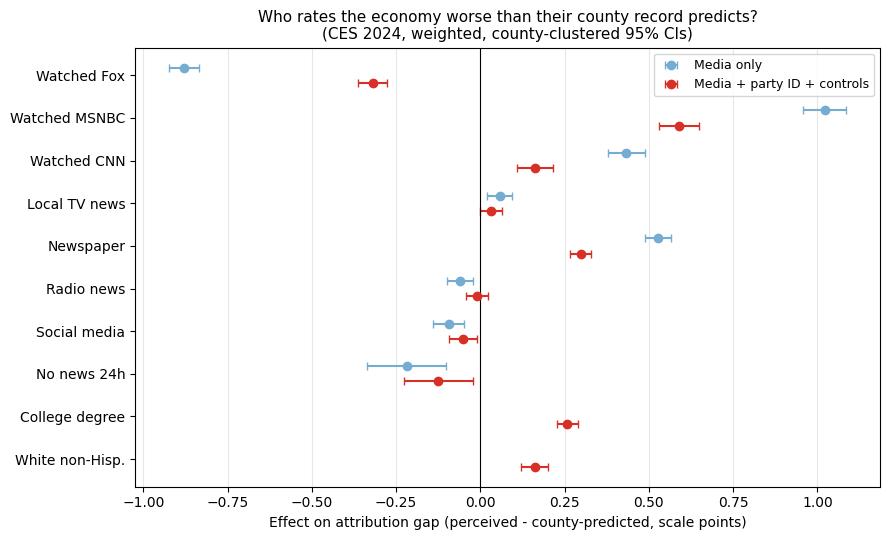

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
order = ['fox', 'msnbc', 'cnn', 'local_tv', 'newspaper', 'radio', 'social', 'no_news', 'college', 'white']
labels = ['Watched Fox', 'Watched MSNBC', 'Watched CNN', 'Local TV news', 'Newspaper', 'Radio news',
          'Social media', 'No news 24h', 'College degree', 'White non-Hisp.']
y = np.arange(len(order))[::-1]
for m, name, color, dy in [(m_gap_media, 'Media only', '#74add1', 0.18),
                           (m_gap_full, 'Media + party ID + controls', '#d73027', -0.18)]:
    for i, v in enumerate(order):
        if v in m.params.index:
            ax.errorbar(m.params[v], y[i] + dy, xerr=1.96 * m.bse[v], fmt='o', color=color, capsize=3,
                        label=name if i == 0 else None)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.set_xlabel('Effect on attribution gap (perceived - county-predicted, scale points)')
ax.set_title('Who rates the economy worse than their county record predicts?\n(CES 2024, weighted, county-clustered 95% CIs)', fontsize=11)
ax.legend(fontsize=9); ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'attribution_gap_media.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Does the gap predict switching?

Among 2024 respondents who recall voting for Biden in 2020 and voted for a major-party candidate in 2024: probability of voting Trump as a function of the attribution gap. Post-election weights; county-clustered SEs; logit via GLM with frequency weights (survey-weight approximation — coefficients are fine, SEs are approximate).

**Caveat on recall.** Recalled 2020 vote in the 2024 wave is 45% Biden / 32% Trump against an actual 51 / 47; Trump 2020 voters are under-reported. The Biden-recaller group is the cleaner one to use.

In [12]:
sw = d1[d1['prior_D'] & d1['voted_2024'] & d1['weight_post'].notna()].copy()
sw['switch_R'] = sw['vote_R_2024']
w = sw['weight_post'] * len(sw) / sw['weight_post'].sum()
print(f'Recalled-Biden voters who voted D/R in 2024: N = {len(sw):,}   '
      f'weighted switch rate to Trump: {wmean(sw["switch_R"], sw["weight_post"]):.1%}')

def wlogit(formula, data, weights):
    return smf.glm(formula, data=data, family=sm.families.Binomial(), freq_weights=weights).fit(
        cov_type='cluster', cov_kwds={'groups': data['county_fips']})

s0 = wlogit('switch_R ~ gap', sw, w)
s1 = wlogit(f'switch_R ~ gap + pid7c + college + age + white', sw, w)
s2 = wlogit(f'switch_R ~ gap + pid7c + college + age + white + {actual_rhs} + fox + msnbc + cnn + local_tv + social', sw, w)

switch_tab = pd.concat([tidy(s0, 'gap_only'), tidy(s1, 'demog'), tidy(s2, 'full')], axis=1).round(3)
switch_tab

Recalled-Biden voters who voted D/R in 2024: N = 20,608   weighted switch rate to Trump: 6.4%


,gap_only_coef,gap_only_se,gap_only_p,demog_coef,demog_se,demog_p,full_coef,full_se,full_p
Intercept,-2.359,0.079,0.0,-4.009,0.359,0.000,-3.807,0.428,0.000
gap,-1.032,0.070,0.0,-0.815,0.083,0.000,-0.827,0.079,0.000
pid7c,NaN,NaN,NaN,0.810,0.048,0.000,0.826,0.048,0.000
college,NaN,NaN,NaN,-0.372,0.163,0.023,-0.340,0.167,0.041
age,NaN,NaN,NaN,-0.009,0.005,0.078,-0.014,0.005,0.005
white,NaN,NaN,NaN,-0.171,0.156,0.272,0.058,0.158,0.713
real_pay_pct_chg_2020_2024_z,NaN,NaN,NaN,NaN,NaN,NaN,-0.011,0.113,0.924
private_emp_pct_chg_2020_2024_z,NaN,NaN,NaN,NaN,NaN,NaN,0.143,0.087,0.102
unemp_rate_z,NaN,NaN,NaN,NaN,NaN,NaN,0.192,0.107,0.074
fox,NaN,NaN,NaN,NaN,NaN,NaN,1.868,0.255,0.000


In [13]:
# Average marginal effect of the gap on P(switch to Trump), full model
def ame(model, data, var, delta=1.0):
    base = model.predict(data)
    hi = data.copy(); hi[var] = hi[var] + delta
    return np.average(model.predict(hi) - base, weights=w)

print('Average marginal effects on P(Biden 2020 voter -> Trump 2024), full model:')
print(f'  gap +1 scale point (economy rated one step better): {ame(s2, sw, "gap"):+.3f}')
print(f'  gap -1 scale point (rated one step worse):          {ame(s2, sw, "gap", -1):+.3f}')
print(f'  watched Fox (0->1):                                 {ame(s2, sw, "fox"):+.3f}')
print(f'  county real pay +1 SD:                              {ame(s2, sw, "real_pay_pct_chg_2020_2024_z"):+.3f}')

# Switch rate by perception level. (Terciles of the gap would lump 'much worse', 'somewhat worse' and
# 'about the same' together because the underlying item has only five values.)
print()
print('Switch-to-Trump rate by rating of the economy (recalled Biden voters):')
print(f'{"rating":18s} {"N":>6s} {"weighted":>9s} {"unweighted":>11s}')
for v, lab in [(-2, 'much worse'), (-1, 'somewhat worse'), (0, 'about the same'), (1, 'somewhat better'), (2, 'much better')]:
    s = sw[sw['perceived_econ'] == v]
    print(f'{lab:18s} {len(s):>6,} {wmean(s["switch_R"], s["weight_post"]):>9.1%} {s["switch_R"].mean():>11.1%}')
print()
print(f'Weights matter here: mean post-weight is {sw.loc[sw["switch_R"] == 1, "weight_post"].mean():.2f} for switchers '
      f'vs {sw.loc[sw["switch_R"] == 0, "weight_post"].mean():.2f} for stayers. The panel over-represents consistent '
      f'Democrats; the weights correct toward a population with more switchers.')

Average marginal effects on P(Biden 2020 voter -> Trump 2024), full model:
  gap +1 scale point (economy rated one step better): -0.025
  gap -1 scale point (rated one step worse):          +0.039
  watched Fox (0->1):                                 +0.113
  county real pay +1 SD:                              -0.000

Switch-to-Trump rate by rating of the economy (recalled Biden voters):
rating                  N  weighted  unweighted
much worse          1,192     31.6%       20.3%
somewhat worse      2,580     11.1%        7.0%
about the same      3,798      4.6%        2.7%
somewhat better     8,746      1.7%        0.8%
much better         4,292      1.5%        0.4%

Weights matter here: mean post-weight is 1.88 for switchers vs 0.84 for stayers. The panel over-represents consistent Democrats; the weights correct toward a population with more switchers.


In [14]:
# Mirror: recalled Trump voters switching to Harris
sw_r = d1[d1['prior_R'] & d1['voted_2024'] & d1['weight_post'].notna()].copy()
sw_r['switch_D'] = 1 - sw_r['vote_R_2024']
w_r = sw_r['weight_post'] * len(sw_r) / sw_r['weight_post'].sum()
s_r = wlogit(f'switch_D ~ gap + pid7c + college + age + white + {actual_rhs}', sw_r, w_r)
print(f'Recalled-Trump voters: N = {len(sw_r):,}   weighted switch rate to Harris: {wmean(sw_r["switch_D"], sw_r["weight_post"]):.1%}')
print(f'  gap coef {s_r.params["gap"]:+.3f} (se {s_r.bse["gap"]:.3f}, p={s_r.pvalues["gap"]:.3f})   '
      f'AME of gap +1: {np.average(s_r.predict(sw_r.assign(gap=sw_r["gap"] + 1)) - s_r.predict(sw_r), weights=w_r):+.3f}')

Recalled-Trump voters: N = 16,166   weighted switch rate to Harris: 2.3%
  gap coef +0.849 (se 0.092, p=0.000)   AME of gap +1: +0.021


## 8. Save

In [15]:
keep = ['caseid', 'county_fips', 'state', 'weight', 'weight_post', 'pid7c', 'pid3c', 'college', 'age', 'white',
        'perceived_econ', 'perceived_income', 'perceived_prices', 'gap',
        'fox', 'msnbc', 'cnn', 'local_tv', 'newspaper', 'radio', 'social', 'no_news',
        'presvote_post_party', 'presvote_prior_party', 'voted_2024', 'vote_R_2024',
        'real_pay_pct_chg_2020_2024_z', 'private_emp_pct_chg_2020_2024_z', 'unemp_rate_z',
        'log_income', 'college_share', 'white_nocollege', 'dem_share_2020', 'swing_2024', 'mfg_share_2016']
d1[keep].to_csv(PROC_DIR / 'ces_2024_attribution.csv', index=False)
stage1.to_csv(TABLES_DIR / 'attribution_stage1.csv')
gap_tab.to_csv(TABLES_DIR / 'attribution_gap_by_group.csv')
gap_models.to_csv(TABLES_DIR / 'attribution_gap_models.csv')
switch_tab.to_csv(TABLES_DIR / 'attribution_switching.csv')
flip.to_csv(TABLES_DIR / 'attribution_partisan_flip.csv')
print('Saved:')
for p in ['data/processed/ces_2024_attribution.csv', 'outputs/tables/attribution_stage1.csv',
          'outputs/tables/attribution_gap_by_group.csv', 'outputs/tables/attribution_gap_models.csv',
          'outputs/tables/attribution_switching.csv', 'outputs/tables/attribution_partisan_flip.csv']:
    print('  ' + p)

Saved:
  data/processed/ces_2024_attribution.csv
  outputs/tables/attribution_stage1.csv
  outputs/tables/attribution_gap_by_group.csv
  outputs/tables/attribution_gap_models.csv
  outputs/tables/attribution_switching.csv
  outputs/tables/attribution_partisan_flip.csv


## Limitations specific to this notebook

- **Reverse causation in the switching model.** Perception is measured pre-election, vote post-election, but a respondent who had already decided to switch to Trump would rate the economy badly *because* of that decision (expressive responding / "follow the leader"). The gap → switching association is consistent with the attribution hypothesis and equally consistent with the reverse. Separating them needs either panel data with perception measured before the decision, or an instrument for perception (local news availability is the candidate).
- **Single-level.** County-clustered SEs handle the dependence but not the cross-level structure; notebook 07 fits the random-intercept model.
- **Media is self-selected.** Fox/MSNBC coefficients net of party ID show association, not effect.
- **Recall bias.** The switching sample is defined by recalled 2020 vote, which under-reports Trump 2020 voters.
- **One county measure of "actual".** Real pay, job growth, and 2020 unemployment. Prices — the grievance of the cycle — vary little across counties in available data; the 2024 `perceived_prices` item is available but has no county-level counterpart.
- **No local-news-environment variable yet.** The Medill news-desert file slots into section 2 when added.